# Spotify User Churn Prediction

## Section 0 | Load & Inspect Data

Load the SQL-built user-level dataset for EDA and machine learning.

In [1]:
# Load the SQL-built feature table
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 140)

data_dir = Path("data")
data_path = data_dir / "user_level_feature_table_sql_built.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Unique users:", df["user_id"].nunique())
print("Churn rate:", round(df["churn_label_14d"].mean(), 4))
print("Total missing values:", df.isna().sum().sum())

df.head()

Dataset shape: (50000, 37)
Unique users: 50000
Churn rate: 0.4756
Total missing values: 6075


,user_id,snapshot_date,signup_date,tenure_days,country,primary_device,acquisition_channel,subscription_type,active_days_30d,listen_events_30d,listen_minutes_30d,sessions_30d,avg_play_duration_sec_30d,skip_rate_30d,completion_rate_30d,liked_songs_30d,playlist_adds_30d,search_events_30d,top_genre_30d,ad_impressions_30d,ad_clicks_30d,ad_click_rate_30d,ad_completions_30d,ad_completion_rate_30d,ad_impressions_per_active_day,ad_revenue_30d,trial_exposed_30d,trial_started_30d,paid_started_30d,renewal_success_30d,payment_failed_30d,cancel_30d,trial_expired_30d,subscription_revenue_30d,total_revenue_30d,churn_label_14d,paid_conversion_30d
0,U000001,2026-04-01,2026-02-06,54,UK,mobile_android,organic_search,individual_premium,1,1,1.933333,1,116.0,0.00,0.0,0,0,0,jazz,3,0,0.0,2,0.666667,3.000000,0.0438,0,0,0,0,0,1,0,0.0,0.0438,0,0
1,U000002,2026-04-01,2026-03-07,25,ES,mobile_android,paid_social,trial,10,10,21.550000,10,129.3,0.20,0.3,1,1,2,rock,7,0,0.0,6,0.857143,0.700000,0.0544,1,0,0,0,0,0,0,0.0,0.0544,1,0
2,U000003,2026-04-01,2025-07-29,246,IN,mobile_android,referral,trial,3,3,6.500000,3,130.0,0.00,0.0,0,0,0,pop,1,0,0.0,0,0.000000,0.333333,0.0025,0,0,0,0,0,0,0,0.0,0.0025,1,0
3,U000004,2026-04-01,2025-11-14,138,FR,mobile_android,referral,trial,4,4,11.333333,4,170.0,0.25,0.0,0,0,3,classical,2,0,0.0,1,0.500000,0.500000,0.0703,0,0,0,0,0,0,0,0.0,0.0703,0,0
4,U000005,2026-04-01,2025-05-21,315,US,mobile_ios,student_partner,free,1,1,2.716667,1,163.0,0.00,0.0,0,0,0,jazz,0,0,0.0,0,0.000000,0.000000,0.0000,0,0,0,0,0,0,0,0.0,0.0000,0,0


## Section 1 | Data Quality & Missing Values

Inspect missing values before exploratory analysis and modeling.

In [4]:
# Identify columns with missing values
missing_summary = df.isna().sum()
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

missing_summary

top_genre_30d    6075
dtype: int64

In [5]:
# Check activity levels for users with missing genre
df.loc[
    df["top_genre_30d"].isna(),
    "active_days_30d"
].value_counts().sort_index()

active_days_30d
0    6075
Name: count, dtype: int64

## Section 2 | Exploratory Data Analysis

### Listening Minutes Distribution

Examine the distribution of listening activity over the observation window.

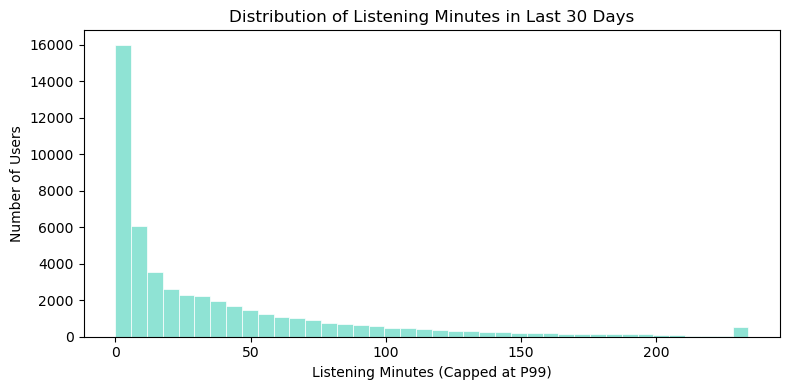

In [13]:
# Cap extreme listening values at P99 for visualization
p99_listen = df['listen_minutes_30d'].quantile(0.99)

df['listen_minutes_30d_capped'] = (
    df['listen_minutes_30d'].clip(upper=p99_listen)
)

# Visualize the distribution of listening minutes
plt.figure(figsize=(8, 4))

plt.hist(
    df['listen_minutes_30d_capped'].dropna(),
    bins=40,
    color="#8FE3D4",
    edgecolor="white",
    linewidth=0.5
)

plt.title('Distribution of Listening Minutes in Last 30 Days')
plt.xlabel('Listening Minutes (Capped at P99)')
plt.ylabel('Number of Users')

plt.tight_layout()
plt.show()

**Insight:** Listening activity is strongly right-skewed, with most
users concentrated at lower listening durations and a smaller
group of highly engaged users forming a long tail.

**Note:** Listening minutes are capped at P99 for visualization
only. The original values are preserved for modeling.

## Section 3 | Listening Activity by Subscription Type

Compare listening duration distributions across subscription types.

,subscription_type,users,avg_listen_minutes,median_listen_minutes,p25_listen_minutes,p75_listen_minutes
0,family_premium,2859,49.951556,30.116667,6.841667,73.433333
2,individual_premium,12766,49.388035,28.716667,7.183333,70.295833
3,student_premium,902,48.992166,27.508333,6.708333,66.637500
4,trial,18113,35.852522,16.033333,3.833333,48.983333
1,free,15360,25.971624,8.416667,2.000000,34.204167


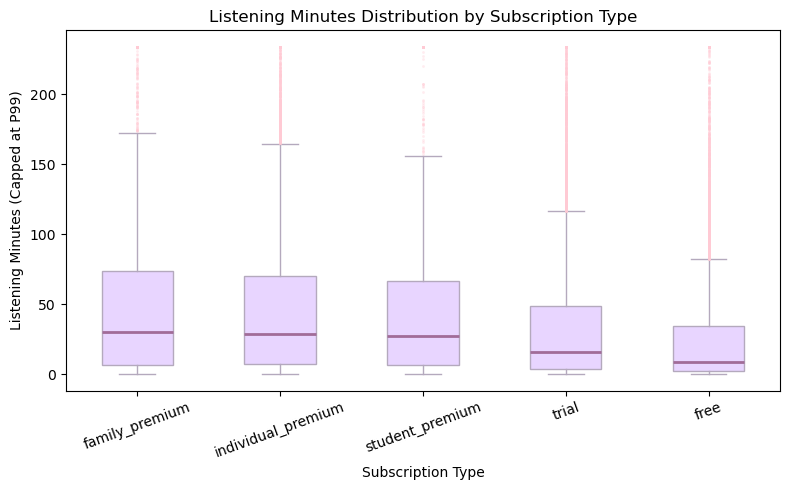

In [14]:
# Compare listening duration across subscription types
box_df = df[
    ['user_id', 'subscription_type', 'listen_minutes_30d']
].dropna().copy()

p99 = box_df['listen_minutes_30d'].quantile(0.99)

box_df['listen_minutes_30d_capped'] = (
    box_df['listen_minutes_30d'].clip(upper=p99)
)

# Calculate summary statistics by subscription type
subscription_summary = (
    box_df.groupby('subscription_type')
    .agg(
        users=('user_id', 'nunique'),
        avg_listen_minutes=('listen_minutes_30d', 'mean'),
        median_listen_minutes=('listen_minutes_30d', 'median'),
        p25_listen_minutes=(
            'listen_minutes_30d',
            lambda x: x.quantile(0.25)
        ),
        p75_listen_minutes=(
            'listen_minutes_30d',
            lambda x: x.quantile(0.75)
        )
    )
    .reset_index()
    .sort_values('median_listen_minutes', ascending=False)
)

display(subscription_summary)

# Prepare data for the boxplot
subscription_order = subscription_summary['subscription_type'].tolist()

data_to_plot = [
    box_df.loc[
        box_df['subscription_type'] == s,
        'listen_minutes_30d_capped'
    ]
    for s in subscription_order
]

# Visualize listening duration by subscription type
plt.figure(figsize=(8, 5))

plt.boxplot(
    data_to_plot,
    tick_labels=subscription_order,
    patch_artist=True,
    boxprops=dict(
        facecolor="#E8D5FF",
        edgecolor="#B4A9BD"
    ),
    medianprops=dict(
        color="#A16C98",
        linewidth=2
    ),
    whiskerprops=dict(color="#B4A9BD"),
    capprops=dict(color="#B4A9BD"),
    flierprops=dict(
        marker="o",
        markersize=2,
        markerfacecolor="#FFCAD4",
        markeredgecolor="none",
        alpha=0.35
    )
)

plt.title('Listening Minutes Distribution by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Listening Minutes (Capped at P99)')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

**Insight:** Premium users have substantially higher median listening
durations (27–30 minutes) compared with free users (8.42 minutes).
Listening activity is right-skewed across all subscription types.

**Next Action:** Investigate whether lower engagement translates into
higher churn risk and greater overall churn contribution.

## Section 4 | Rate vs Contribution

Identify which activity segments contribute the most to total churn,
rather than focusing only on churn rates.

In [15]:
# Define activity segments based on active days
df["active_level"] = np.select(
    [
        df["active_days_30d"] == 0,
        df["active_days_30d"].between(1, 3),
        df["active_days_30d"].between(4, 10)
    ],
    ["inactive", "low", "medium"],
    default="high"
)

# Calculate churn rate and contribution by activity segment
segment_col = "active_level"
metric_col = "churn_label_14d"

temp = df[[segment_col, metric_col, "user_id"]].dropna()

contribution_summary = (
    temp.groupby(segment_col, observed=True)
    .agg(
        users=("user_id", "nunique"),
        metric_rate=(metric_col, "mean"),
        metric_users=(metric_col, "sum")
    )
    .reset_index()
)

total_metric_users = contribution_summary["metric_users"].sum()

contribution_summary["contribution_share"] = (
    contribution_summary["metric_users"] / total_metric_users
)

contribution_summary = contribution_summary.sort_values(
    "contribution_share", ascending=False
)

display(contribution_summary)

,active_level,users,metric_rate,metric_users,contribution_share
2,low,15323,0.662794,10156,0.427100
3,medium,18229,0.427944,7801,0.328063
1,inactive,6075,0.770864,4683,0.196938
0,high,10373,0.109804,1139,0.047899


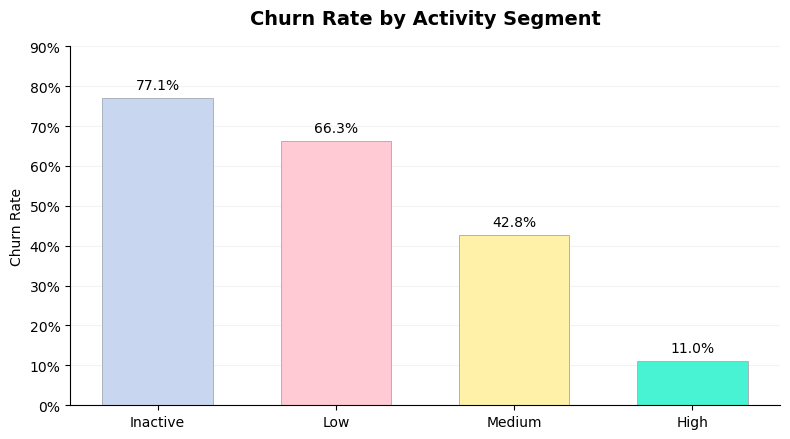

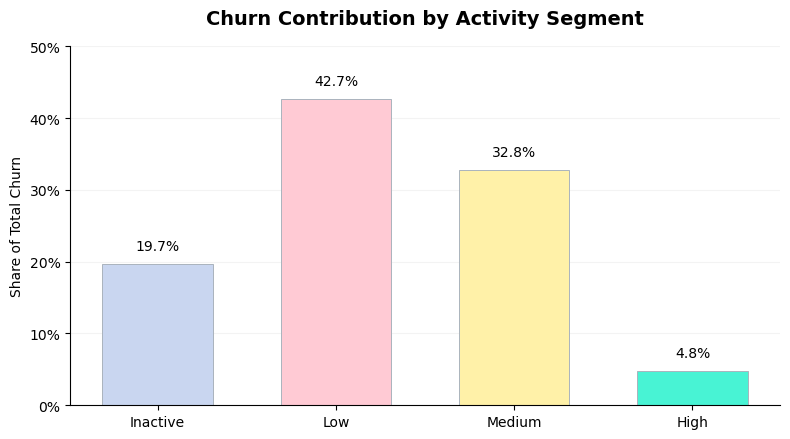

In [16]:
from matplotlib.ticker import PercentFormatter

# Define activity segment order and macaron color palette
segment_order = ["inactive", "low", "medium", "high"]

segment_colors = {
    "inactive": "#C9D6F0",
    "low": "#FFCAD4",
    "medium": "#FFF1A8",
    "high": "#48F3D4"
}

plot_df = contribution_summary.set_index("active_level").loc[segment_order]

colors = [segment_colors[s] for s in segment_order]
labels = [s.title() for s in segment_order]

# Compare churn rate and contribution in separate charts
for column, title, ylabel, ymax in [
    ("metric_rate", "Churn Rate by Activity Segment", "Churn Rate", 0.9),
    ("contribution_share", "Churn Contribution by Activity Segment",
     "Share of Total Churn", 0.5)
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))

    values = plot_df[column]

    bars = ax.bar(
        labels,
        values,
        color=colors,
        edgecolor="#AAB3BD",
        linewidth=0.7,
        width=0.62
    )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=16)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))

    # Display percentage labels above each bar
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.015,
            f"{value:.1%}",
            ha="center",
            va="bottom",
            fontsize=10
        )

    # Simplify borders and gridlines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

**Insight:** Inactive users have the highest churn rate (77.09%),
but low-activity users account for the largest share of total
churn (42.71%). Low- and medium-activity users together
contribute 75.52% of all churn cases.

**Business Implication:** Churn rate alone is insufficient for
prioritizing retention efforts. User segment size and total
churn contribution must also be considered.

**Recommendation:** Prioritize low-activity users for targeted
re-engagement experiments, while evaluating intervention
effectiveness and costs before scaling.

## Section 5 | Cohort Quality Analysis

Compare churn rates and engagement across signup cohorts to identify differences in user retention.

,signup_month,users,churn_rate,avg_active_days,retention_rate
0,2025-01,1370,0.470803,6.441606,0.529197
1,2025-02,2098,0.451382,6.444709,0.548618
2,2025-03,2571,0.453520,6.406068,0.546480
3,2025-04,3027,0.476049,6.252065,0.523951
4,2025-05,3281,0.478817,6.425175,0.521183
5,2025-06,3439,0.482408,6.319570,0.517592
6,2025-07,3886,0.468091,6.374678,0.531909
7,2025-08,4000,0.483000,6.263500,0.517000
8,2025-09,3960,0.468939,6.183081,0.531061
9,2025-10,4236,0.464353,6.343484,0.535647


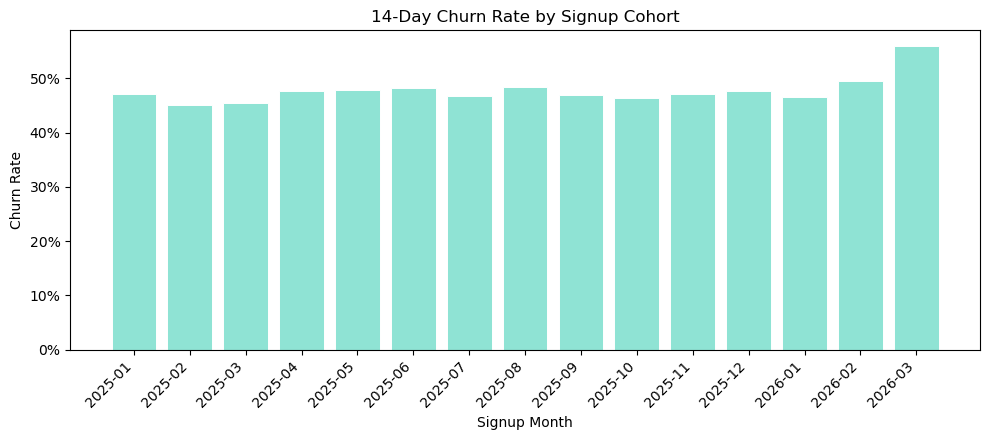

In [17]:
# Create signup cohorts based on registration month
df["signup_month"] = (
    pd.to_datetime(df["signup_date"])
    .dt.to_period("M")
    .astype(str)
)

# Calculate churn and engagement by signup cohort
cohort_summary = (
    df.groupby("signup_month")
    .agg(
        users=("user_id", "nunique"),
        churn_rate=("churn_label_14d", "mean"),
        avg_active_days=("active_days_30d", "mean")
    )
    .reset_index()
    .sort_values("signup_month")
)

cohort_summary["retention_rate"] = 1 - cohort_summary["churn_rate"]

display(cohort_summary)

# Visualize churn rate across signup cohorts
plt.figure(figsize=(10, 4.5))

plt.bar(
    cohort_summary["signup_month"],
    cohort_summary["churn_rate"],
    color="#8FE3D4",
    edgecolor="white",
    linewidth=0.7
)

plt.title("14-Day Churn Rate by Signup Cohort")
plt.xlabel("Signup Month")
plt.ylabel("Churn Rate")
plt.xticks(rotation=45, ha="right")

from matplotlib.ticker import PercentFormatter
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()

**Insight:** Users who signed up in March 2026 have the highest
14-day churn rate (56.02%), compared with approximately 45–49%
for most earlier cohorts.

**Business Implication:** Newer users may face greater churn risk,
although differences in user tenure and engagement could explain
part of this pattern.

**Next Action:** Include tenure and engagement features in the
churn prediction model.

## Section 6 | Prepare Features & Target

Select numerical and categorical features for predicting 14-day
user churn while excluding future outcomes to prevent data leakage.

In [18]:
# Define numerical and categorical features
numeric_features = [
    "active_days_30d",
    "listen_minutes_30d",
    "sessions_30d",
    "playlist_adds_30d",
    "liked_songs_30d",
    "search_events_30d",
    "skip_rate_30d",
    "ad_impressions_per_active_day",
    "tenure_days"
]

categorical_features = [
    "subscription_type",
    "primary_device",
    "acquisition_channel",
    "country",
    "top_genre_30d"
]

target_col = "churn_label_14d"

# Preserve users with no listening history
model_df = df.copy()
model_df["top_genre_30d"] = model_df["top_genre_30d"].fillna("unknown")

# Separate features (X) and target (y)
X = model_df[numeric_features + categorical_features].copy()
y = model_df[target_col].astype(int)

print("Feature shape:", X.shape)
print("Target distribution:")
print(y.value_counts(normalize=True))

Feature shape: (50000, 14)
Target distribution:
churn_label_14d
0    0.52442
1    0.47558
Name: proportion, dtype: float64


## Section 7 | Train/Test Split

Split the dataset into training and testing sets using an 80/20
ratio with stratified sampling.

In [19]:
from sklearn.model_selection import train_test_split

# Split data while preserving the churn rate in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4))
print("Test churn rate:", round(y_test.mean(), 4))

Train shape: (40000, 14)
Test shape: (10000, 14)
Train churn rate: 0.4756
Test churn rate: 0.4756


## Section 8 | Preprocessing Pipeline

Standardize numerical features and apply one-hot encoding to categorical features.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Standardize numerical features
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

# Encode categorical features
categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine numerical and categorical preprocessing
preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline ready!")

Preprocessing pipeline ready!


## Section 9 | Logistic Regression

Train a baseline classification model to predict 14-day churn probability.

In [21]:
from sklearn.linear_model import LogisticRegression

# Train Logistic Regression with preprocessing
log_model = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

log_model.fit(X_train, y_train)

log_pred = log_model.predict(X_test)
log_proba = log_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed.")
print("First 5 churn probabilities:", np.round(log_proba[:5], 4))

Logistic Regression training completed.
First 5 churn probabilities: [0.721  0.752  0.7687 0.2862 0.7916]


## Section 10 | Random Forest

Train a Random Forest classifier to capture nonlinear relationships in user behavior.

In [22]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest with preprocessing
rf_model = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed.")
print("First 5 churn probabilities:", np.round(rf_proba[:5], 4))

Random Forest training completed.
First 5 churn probabilities: [0.6683 0.699  0.7593 0.248  0.689 ]


## Section 11 | Model Evaluation

Compare Logistic Regression and Random Forest using accuracy,
precision, recall, F1-score, ROC-AUC, and PR-AUC.

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Evaluate classification performance
def evaluate_model(model_name, y_true, y_pred, y_proba):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba)
    }

# Compare both models on the test set
model_results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, log_pred, log_proba),
    evaluate_model("Random Forest", y_test, rf_pred, rf_proba)
])

model_results

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.7138,0.670018,0.784693,0.722836,0.784215,0.729426
1,Random Forest,0.7049,0.657148,0.793524,0.718926,0.780580,0.723480


## Section 12 | Confusion Matrix

Examine true positives, false positives, true negatives,
and false negatives for both churn prediction models.

In [24]:
from sklearn.metrics import confusion_matrix

# Display confusion matrices for both models
def show_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Not Churn", "Actual Churn"],
        columns=["Predicted Not Churn", "Predicted Churn"]
    )

    return cm_df

print("Logistic Regression Confusion Matrix")
display(show_confusion_matrix(y_test, log_pred))

print("Random Forest Confusion Matrix")
display(show_confusion_matrix(y_test, rf_pred))

Logistic Regression Confusion Matrix


,Predicted Not Churn,Predicted Churn
Actual Not Churn,3406,1838
Actual Churn,1024,3732


Random Forest Confusion Matrix


,Predicted Not Churn,Predicted Churn
Actual Not Churn,3275,1969
Actual Churn,982,3774


**Insight:** Logistic Regression slightly outperforms Random Forest
in accuracy (71.38% vs. 70.49%), F1-score (0.7228 vs. 0.7189),
and ROC-AUC (0.7842 vs. 0.7806).

Random Forest achieves slightly higher recall (79.35% vs. 78.47%),
identifying 42 additional churned users but producing 131 more
false positives.

**Business Implication:** Logistic Regression is a strong baseline,
while the choice of model and classification threshold should
depend on the cost of missed churn and unnecessary interventions.

## Section 13 | Threshold Analysis

Examine the precision-recall trade-off at different classification thresholds.

In [25]:
# Evaluate model performance across classification thresholds
def evaluate_threshold(y_true, y_proba, threshold):
    y_pred = (y_proba >= threshold).astype(int)

    return {
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "predicted_churn_share": y_pred.mean()
    }

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = pd.DataFrame([
    evaluate_threshold(y_test, rf_proba, t)
    for t in thresholds
])

threshold_results

,threshold,precision,recall,f1,predicted_churn_share
0,0.2,0.551192,0.976871,0.704740,0.8429
1,0.3,0.588858,0.935660,0.722813,0.7557
2,0.4,0.618893,0.881623,0.727257,0.6775
3,0.5,0.657148,0.793524,0.718926,0.5743
4,0.6,0.709461,0.622792,0.663308,0.4175
5,0.7,0.780756,0.342935,0.476552,0.2089


**Insight:** A threshold of 0.4 achieves the highest F1-score (0.7273)
among the evaluated values. It improves recall to 88.16%, compared
with 79.35% at the default threshold of 0.5, at the cost of lower
precision and a larger predicted high-risk population.

**Business Implication:** Lower thresholds may support broader
retention outreach, but increase intervention costs. Final threshold
selection should use validation data and business constraints.

## Section 14 | Random Forest Hyperparameter Optimization

Compare different tree depths and minimum leaf sizes to assess
their impact on churn prediction performance.

In [26]:
# Compare Random Forest configurations
rf_configs = [
    {"max_depth": 4, "min_samples_leaf": 30},
    {"max_depth": 6, "min_samples_leaf": 20},
    {"max_depth": 8, "min_samples_leaf": 10}
]

optimization_results = []

for config in rf_configs:
    model = Pipeline(
        steps=[
            ("preprocess", preprocess),
            ("model", RandomForestClassifier(
                n_estimators=300,
                max_depth=config["max_depth"],
                min_samples_leaf=config["min_samples_leaf"],
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    optimization_results.append(
        evaluate_model(
            f"RF_depth_{config['max_depth']}_leaf_{config['min_samples_leaf']}",
            y_test,
            pred,
            proba
        )
    )

optimization_results = pd.DataFrame(optimization_results)

optimization_results

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,RF_depth_4_leaf_30,0.7007,0.649534,0.805088,0.718994,0.777533,0.722312
1,RF_depth_6_leaf_20,0.7049,0.657148,0.793524,0.718926,0.780580,0.723480
2,RF_depth_8_leaf_10,0.7077,0.662760,0.784693,0.718591,0.782138,0.725814


**Insight:** Increasing Random Forest complexity slightly improves
accuracy and ROC-AUC, but produces no meaningful improvement in
F1-score. All three configurations achieve an F1-score near 0.719.

**Decision:** Retain the original Random Forest configuration
(max_depth=6, min_samples_leaf=20) for further analysis.

## Section 15 | Feature Names After Preprocessing

Retrieve feature names after numerical scaling and categorical encoding.

In [27]:
# Retrieve transformed feature names from the fitted pipeline
def get_feature_names_from_pipeline(pipeline_model):
    preprocessor = pipeline_model.named_steps["preprocess"]
    return preprocessor.get_feature_names_out()

feature_names = get_feature_names_from_pipeline(log_model)

feature_names[:10]

array(['num__active_days_30d', 'num__listen_minutes_30d',
       'num__sessions_30d', 'num__playlist_adds_30d',
       'num__liked_songs_30d', 'num__search_events_30d',
       'num__skip_rate_30d', 'num__ad_impressions_per_active_day',
       'num__tenure_days', 'cat__subscription_type_family_premium'],
      dtype=object)

## Section 16 | Logistic Regression Coefficients

Examine model coefficients and odds ratios to interpret churn predictions.

In [28]:
# Extract Logistic Regression coefficients
log_classifier = log_model.named_steps["model"]
feature_names = get_feature_names_from_pipeline(log_model)

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": log_classifier.coef_[0]
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])

coef_df.sort_values(
    "abs_coefficient",
    ascending=False
).head(20)

,feature,coefficient,abs_coefficient,odds_ratio
2,num__sessions_30d,-0.806173,0.806173,0.446564
0,num__active_days_30d,-0.423956,0.423956,0.654452
24,cat__acquisition_channel_referral,-0.381128,0.381128,0.683090
10,cat__subscription_type_free,0.351572,0.351572,1.421300
23,cat__acquisition_channel_paid_social,0.347807,0.347807,1.415959
9,cat__subscription_type_family_premium,-0.277308,0.277308,0.757821
11,cat__subscription_type_individual_premium,-0.268869,0.268869,0.764244
49,cat__top_genre_30d_true_crime_podcast,-0.223352,0.223352,0.799833
50,cat__top_genre_30d_unknown,0.204454,0.204454,1.226856
12,cat__subscription_type_student_premium,-0.162735,0.162735,0.849817


**Insight:** Listening sessions and active days have the strongest
negative coefficients, suggesting that user engagement is an
important predictor of churn.

Subscription type and acquisition channel also contribute to
model predictions, although categorical coefficients require
careful interpretation.

**Business Implication:** Re-engagement strategies targeting
users with declining activity may be worth testing. Model
coefficients indicate associations, not causal effects.

## Section 17 | Random Forest Feature Importance

Identify the most influential features in the Random Forest
churn prediction model.

In [29]:
# Extract feature importance from the trained Random Forest
rf_classifier = rf_model.named_steps["model"]
feature_names = get_feature_names_from_pipeline(rf_model)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

importance_df.head(20)

,feature,importance
2,num__sessions_30d,0.240772
0,num__active_days_30d,0.239103
1,num__listen_minutes_30d,0.148662
5,num__search_events_30d,0.098108
4,num__liked_songs_30d,0.063330
3,num__playlist_adds_30d,0.053994
6,num__skip_rate_30d,0.045470
50,cat__top_genre_30d_unknown,0.022827
11,cat__subscription_type_individual_premium,0.020645
10,cat__subscription_type_free,0.019218


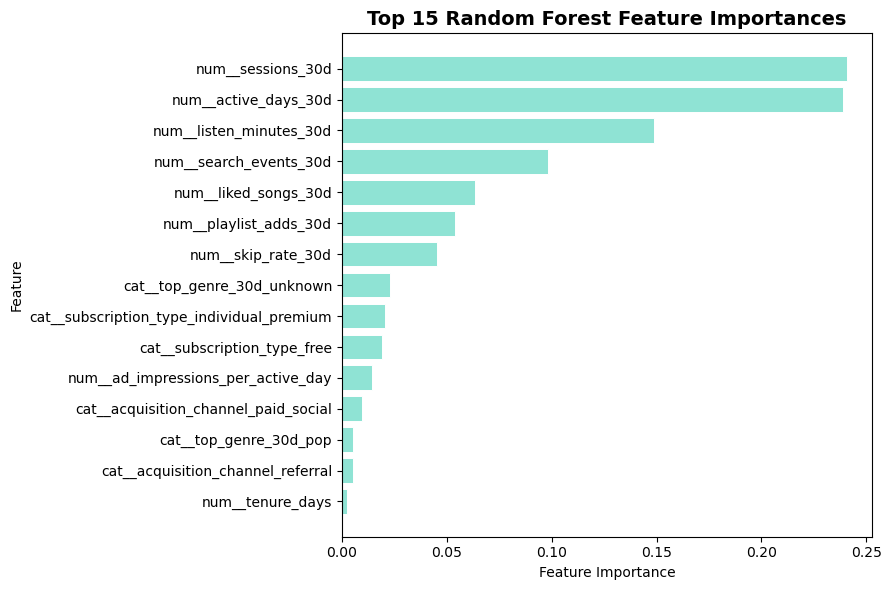

In [30]:
# Visualize the 15 most important features
top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["feature"],
    top_features["importance"],
    color="#8FE3D4",
    edgecolor="white",
    linewidth=0.7
)

plt.title("Top 15 Random Forest Feature Importances",
          fontsize=14, fontweight="bold")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Section 18 | Business Risk Segmentation

Segment users by predicted churn risk to support targeted
retention strategies.

In [31]:
# Segment test users based on predicted churn risk
scoring_df = X_test.copy()

scoring_df["actual_churn"] = y_test.values
scoring_df["rf_churn_probability"] = rf_proba

scoring_df["risk_segment"] = pd.cut(
    scoring_df["rf_churn_probability"],
    bins=[-0.01, 0.4, 0.7, 1.0],
    labels=["low risk", "medium risk", "high risk"]
)

# Compare predicted risk with observed churn
risk_summary = (
    scoring_df.groupby("risk_segment", observed=True)
    .agg(
        users=("rf_churn_probability", "count"),
        avg_predicted_risk=("rf_churn_probability", "mean"),
        actual_churn_rate=("actual_churn", "mean")
    )
    .reset_index()
)

risk_summary

,risk_segment,users,avg_predicted_risk,actual_churn_rate
0,low risk,3225,0.209421,0.174574
1,medium risk,4686,0.574252,0.546735
2,high risk,2089,0.751893,0.780756


## Key Findings & Business Recommendations

**Finding 1 — Engagement is the strongest predictive signal.**

Listening sessions, active days, and listening minutes account
for approximately 62.85% of total Random Forest feature importance.

**Finding 2 — Risk segments show clear differences in actual churn.**

The high-risk segment has a 78.08% observed churn rate, compared
with 54.67% for medium-risk and 17.46% for low-risk users.

**Business Recommendations:**

- High-risk users: Test personalized re-engagement campaigns.
- Medium-risk users: Explore scalable recommendations and playlist
  discovery strategies, given their large contribution to churn.
- Low-risk users: Maintain engagement through personalized content.

**Limitations:** Feature importance does not establish causality.
Risk probabilities have not been formally calibrated. Retention
strategies should be validated through randomized A/B testing
before broader deployment.